# EDA: Cristiano Ronaldo — карьера в голах

**Датасет:** Cristiano Ronaldo Complete Goal Dataset (Kaggle Ready)  
**Объём:** 816 голов, 16 колонок (каждая строка — один гол)  
**Цель:** исследовать результативность по сезонам, турнирам, минутам и способам голов.

> Все графики сохраняются в `../assets/plots/` в PNG 300 dpi 

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import sys


sys.path.append('..')

from src.data_loader import load_data

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["savefig.bbox"] = "tight"

PLOTS_DIR = Path("../assets/plots")
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

print("Библиотеки загружены, функция load_data импортирована.")

Библиотеки загружены, функция load_data импортирована.


In [ ]:

df = load_data(filepath="../data/ronaldo_goals_kaggle_ready.csv")


print(f"Размер датасета: {df.shape[0]} строк, {df.shape[1]} колонок")
print("\nТипы данных и пропуски:")
df.info()

Размер датасета: 816 строк, 19 колонок

Типы данных и пропуски:
<class 'pandas.DataFrame'>
RangeIndex: 816 entries, 0 to 815
Data columns (total 19 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   competition         816 non-null    str           
 1   stage               816 non-null    str           
 2   match_date          816 non-null    datetime64[us]
 3   home_away           816 non-null    str           
 4   team                816 non-null    str           
 5   opponent            816 non-null    str           
 6   final_score         816 non-null    str           
 7   player_position     816 non-null    str           
 8   goal_minute         816 non-null    str           
 9   score_after_goal    816 non-null    str           
 10  goal_method         816 non-null    str           
 11  assist_player       816 non-null    str           
 12  season              816 non-null    str           
 1

In [ ]:

missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(1)
}).sort_values("missing_pct", ascending=False)

display(missing[missing["missing_count"] > 0])

print("\nЧисловые колонки — описательная статистика:")
display(df.describe().T.round(2))

,missing_count,missing_pct



Числовые колонки — описательная статистика:


,count,mean,std,min,25%,50%,75%,max
is_home_goal,816.0,0.57,0.5,0.0,0.0,1.0,1.0,1.0


## Подготовка данных

На этом шаге:
- приводим `match_date` к типу datetime;
- создаём `season_start` для сортировки сезонов;
- создаём `minute_approx` (середину интервала) для тепловой карты.

In [4]:
categorical_cols = [
    "competition", "stage", "home_away", "team", "opponent",
    "player_position", "goal_method", "goal_decade", "goal_minute_bucket"
]

for col in categorical_cols:
    if col in df.columns:
        uniq = df[col].dropna().unique()
        print(f"\n--- {col} ({df[col].nunique()} уникальных) ---")
        print(sorted(uniq)[:15]) 


--- competition (20 уникальных) ---
['AFC Champions League ', 'Champions League Qu. ', 'Club World Cup ', 'Copa del Rey ', 'EFL Cup ', 'Europa League ', 'FA Cup ', 'Italy Cup ', "King's Cup ", 'LaLiga ', 'Liga Portugal ', 'Premier League ', 'Saudi Pro League ', 'Saudi Super Cup ', 'Serie A ']

--- stage (47 уникальных) ---
['1', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '2', '20', '21', '22']

--- home_away (2 уникальных) ---
['Away', 'Home']

--- team (5 уникальных) ---
['Al-Nassr FC', 'Juventus FC', 'Manchester United', 'Real Madrid', 'Sporting CP']

--- opponent (155 уникальных) ---
['AC Milan', 'ACF Fiorentina', 'AJ Auxerre', 'APOEL Nicosia', 'AS Roma', 'Abha Club', 'Ajax Amsterdam', 'Al-Adalah FC', 'Al-Ahli SFC', 'Al-Ain FC', 'Al-Duhail SC', 'Al-Ettifaq FC', 'Al-Fateh SC', 'Al-Fayha FC', 'Al-Gharafa SC']

--- player_position (5 уникальных) ---
['CF', 'LW', 'Not Applicable', 'RW', 'SS']

--- goal_method (12 уникальных) ---
['Counter attack goal', 'Deflected shot 

## 1. Сколько голов Роналду забивал в каждом сезоне

Сортируем сезоны по `season_start`, чтобы график шёл в хронологическом порядке.

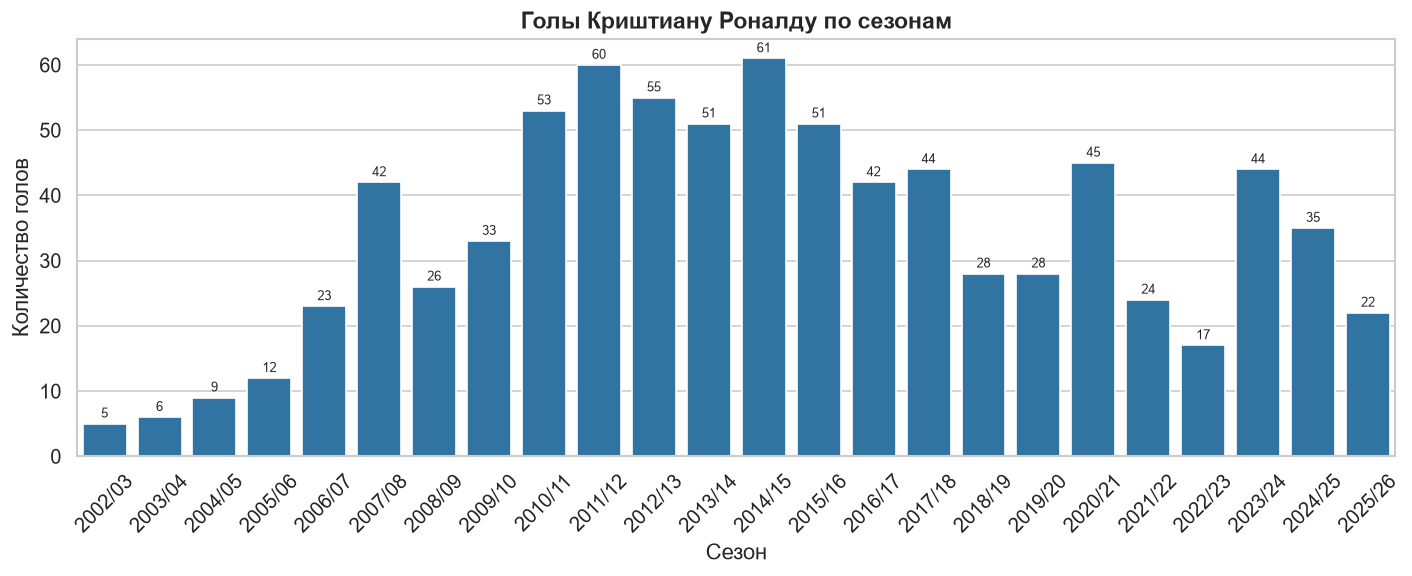

In [15]:
season_goals = (
    df.dropna(subset=["season_start"])
    .groupby(["season_start", "season"])
    .size()
    .reset_index(name="goals")
    .sort_values("season_start")
)

fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(
    data=season_goals,
    x="season",
    y="goals",
    color="#1f77b4",
    ax=ax
)
ax.set_title("Голы Криштиану Роналду по сезонам", fontsize=14, weight="bold")
ax.set_xlabel("Сезон")
ax.set_ylabel("Количество голов")
ax.tick_params(axis="x", rotation=45)

for container in ax.containers:
    ax.bar_label(container, fontsize=8, padding=2)

plt.tight_layout()
plt.savefig(PLOTS_DIR / "goals_by_season.png")
plt.show()

## 2. В каких турнирах Роналду забивал чаще всего

Смотрим абсолютное число голов по топ-10 турнирам.

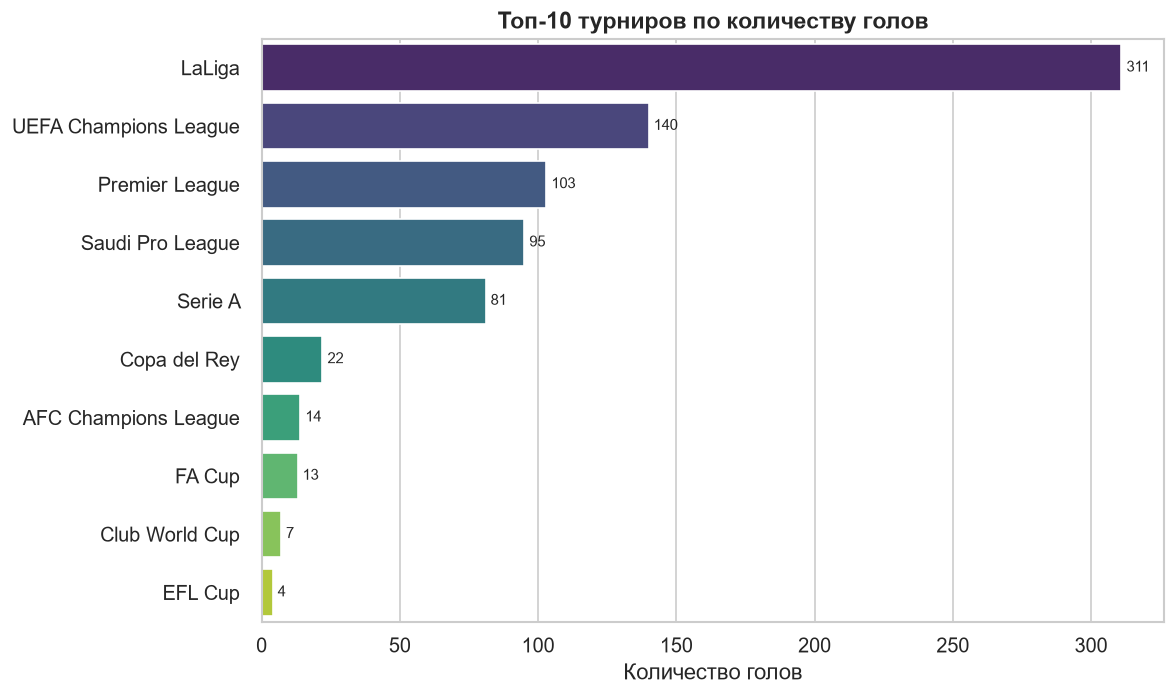

In [ ]:
competition_counts = (
    df["competition"]
    .value_counts()
    .head(10)
    .reset_index()
)
competition_counts.columns = ["competition", "goals"]

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    data=competition_counts,
    y="competition",
    x="goals",
    hue="competition",  
    palette="viridis",
    legend=False,       
    ax=ax
)
ax.set_title("Топ-10 турниров по количеству голов", fontsize=14, weight="bold")
ax.set_xlabel("Количество голов")
ax.set_ylabel("")

for container in ax.containers:
    ax.bar_label(container, fontsize=9, padding=3)

plt.tight_layout()
plt.savefig(PLOTS_DIR / "goals_by_competition.png")
plt.show()

## 3. В какие отрезки матча Роналду забивает чаще

Так как точных минут нет, используем готовые 15-минутные интервалы (`goal_minute_bucket`).

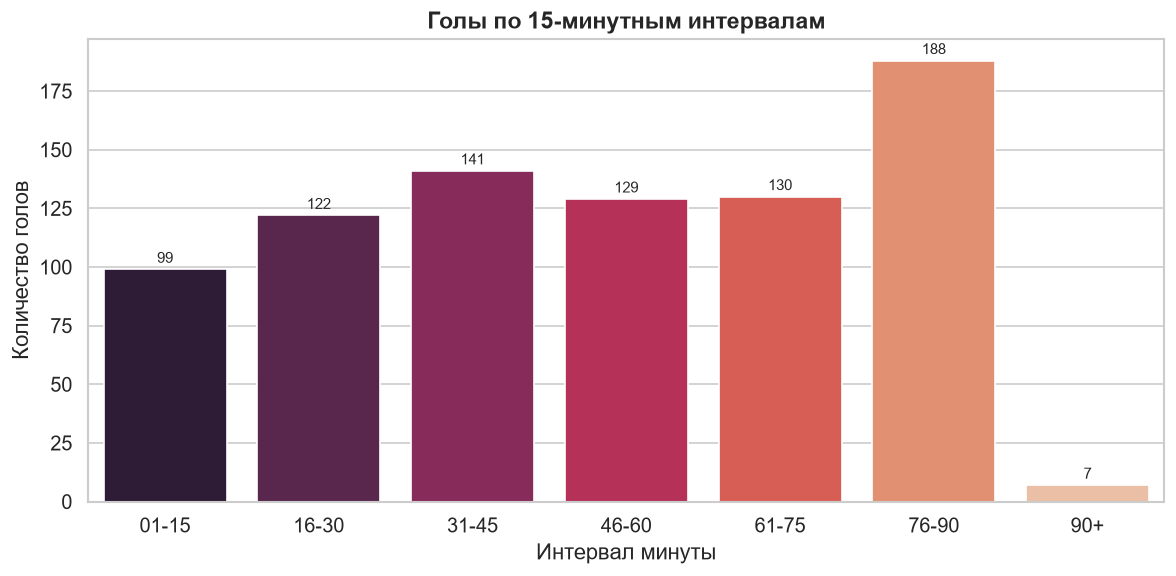

In [ ]:
interval_counts = (
    df["goal_minute_bucket"]
    .value_counts()
    .reset_index()
)
interval_counts.columns = ["interval", "goals"]
interval_counts = interval_counts.sort_values("interval")

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    data=interval_counts,
    x="interval",
    y="goals",
    hue="interval",      
    palette="rocket",
    legend=False, 
    ax=ax
)
ax.set_title("Голы по 15-минутным интервалам", fontsize=14, weight="bold")
ax.set_xlabel("Интервал минуты")
ax.set_ylabel("Количество голов")

for container in ax.containers:
    ax.bar_label(container, fontsize=9, padding=2)

plt.tight_layout()
plt.savefig(PLOTS_DIR / "goals_by_minute_interval.png")
plt.show()

## 4. Как Роналду забивает: пенальти, штрафные, головой и т.д.

Разбивка голов по способу (`goal_method`).

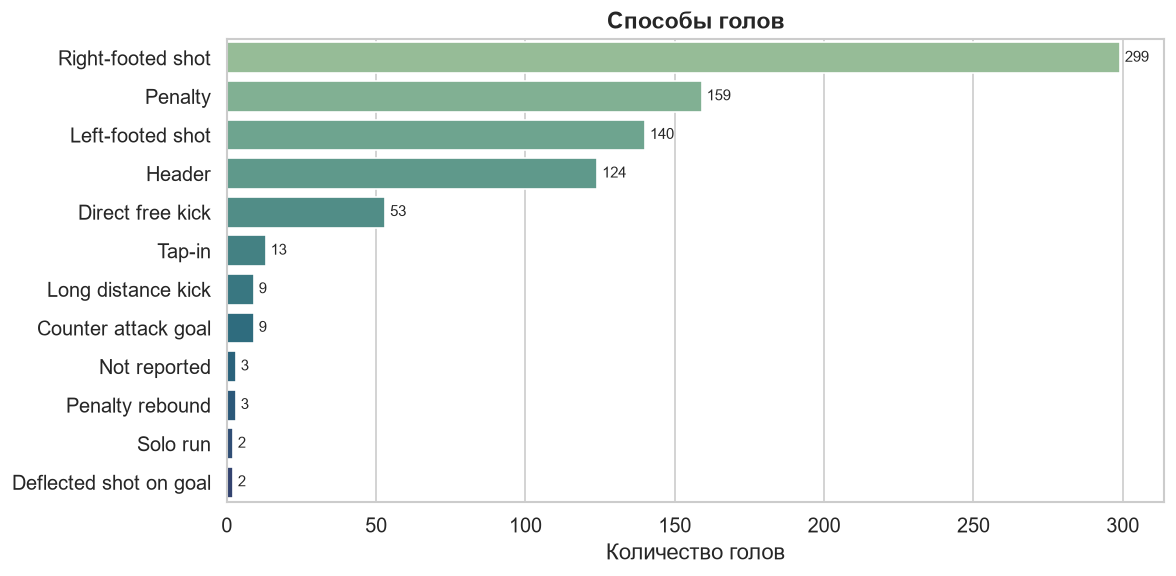

In [19]:
method_counts = (
    df["goal_method"]
    .fillna("Unknown")
    .value_counts()
    .reset_index()
)
method_counts.columns = ["goal_method", "goals"]

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    data=method_counts,
    y="goal_method",
    x="goals",
    hue="goal_method",   
    palette="crest",
    legend=False,
    ax=ax
)
ax.set_title("Способы голов", fontsize=14, weight="bold")
ax.set_xlabel("Количество голов")
ax.set_ylabel("")

for container in ax.containers:
    ax.bar_label(container, fontsize=9, padding=3)

plt.tight_layout()
plt.savefig(PLOTS_DIR / "goal_methods.png")
plt.show()

## 5. Дома или в гостях?

Используем готовую производную колонку `is_home_goal`.

Уникальные значения is_home_goal: [1 0]
Уникальные значения home_away: <StringArray>
['Home', 'Away']
Length: 2, dtype: str


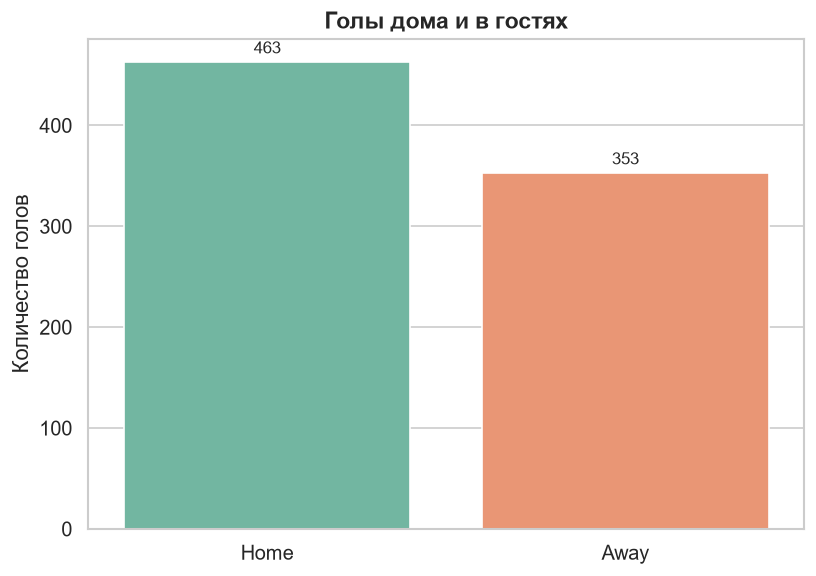

In [ ]:

print("Уникальные значения is_home_goal:", df["is_home_goal"].dropna().unique()[:5])
print("Уникальные значения home_away:", df["home_away"].dropna().unique()[:5])


if "home_away" in df.columns and df["home_away"].notna().any():
    home_away = df["home_away"].value_counts().reset_index()
    home_away.columns = ["venue", "goals"]
else:
    home_away = (
        df["is_home_goal"]
        .astype(str)           
        .str.lower()           
        .map({
            "true": "Дома", "1": "Дома", "1.0": "Дома", 
            "false": "В гостях", "0": "В гостях", "0.0": "В гостях"
        })
        .fillna("Неизвестно")
        .value_counts()
        .reset_index()
    )
    home_away.columns = ["venue", "goals"]


fig, ax = plt.subplots(figsize=(7, 5))
sns.barplot(
    data=home_away,
    x="venue",
    y="goals",
    hue="venue",
    palette="Set2",
    legend=False,
    ax=ax
)
ax.set_title("Голы дома и в гостях", fontsize=14, weight="bold")
ax.set_xlabel("")
ax.set_ylabel("Количество голов")

for container in ax.containers:
    ax.bar_label(container, fontsize=10, padding=3)

plt.tight_layout()
plt.savefig(PLOTS_DIR / "home_away_goals.png")
plt.show()

## 6. Тепловая карта: сезон × 15-минутный интервал

Показывает, в какие сезоны и в какие отрезки матча Роналду был особенно результативен.

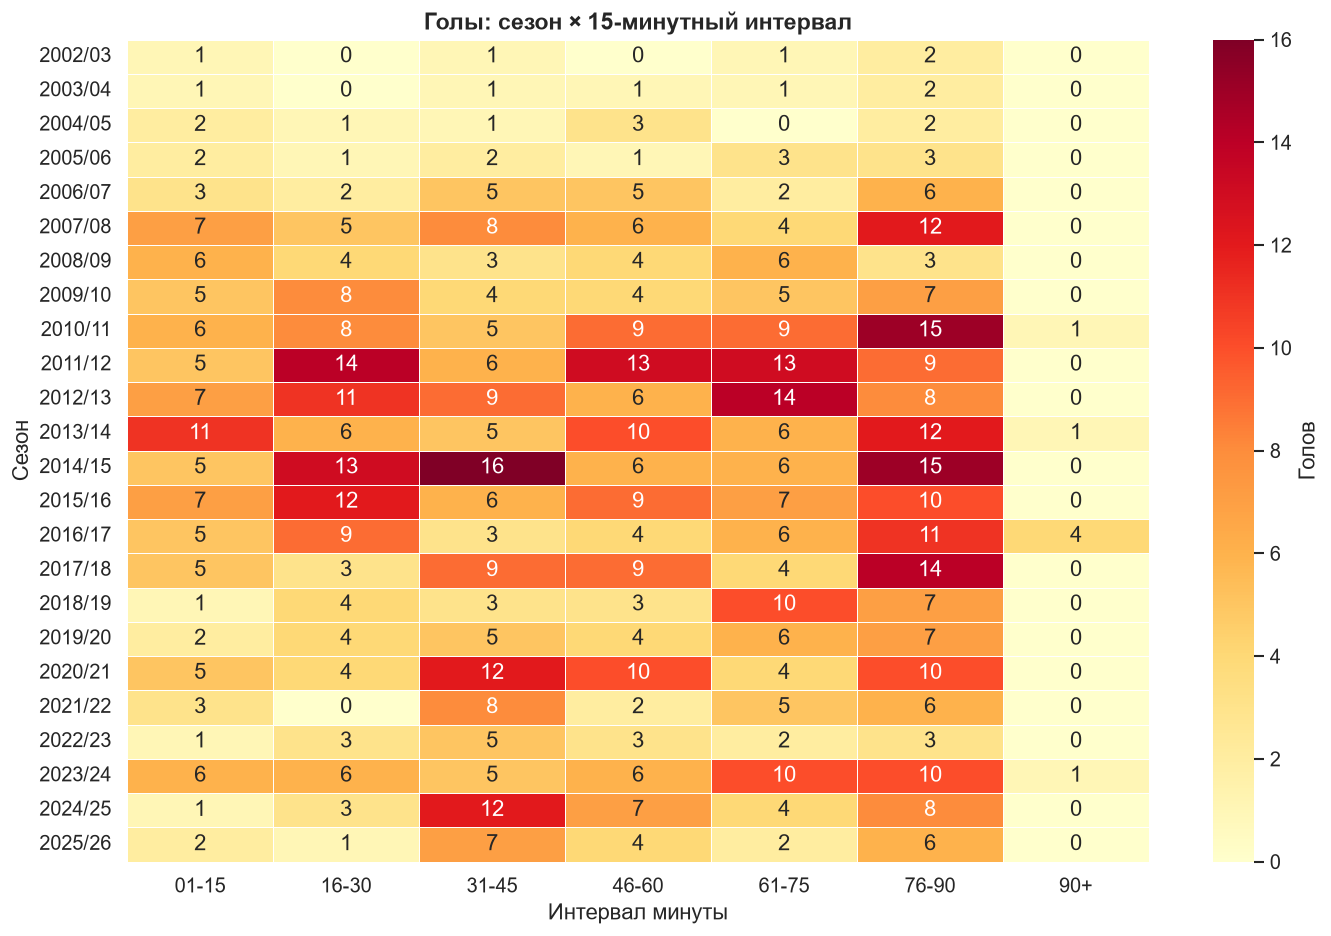

In [ ]:

pivot = pd.crosstab(
    index=df["season"], 
    columns=df["goal_minute_bucket"]
)


season_order = (
    df.dropna(subset=["season", "season_start"])
    .drop_duplicates("season")
    .sort_values("season_start")["season"]
    .tolist()
)
pivot = pivot.reindex([s for s in season_order if s in pivot.index])


minute_order = ['01-15', '16-30', '31-45', '46-60', '61-75', '76-90', '90+']
existing_cols = [col for col in minute_order if col in pivot.columns]
pivot = pivot[existing_cols]

fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(
    pivot,
    cmap="YlOrRd",
    linewidths=0.4,
    annot=True,
    fmt="d",
    cbar_kws={"label": "Голов"},
    ax=ax
)
ax.set_title("Голы: сезон × 15-минутный интервал", fontsize=14, weight="bold")
ax.set_xlabel("Интервал минуты")
ax.set_ylabel("Сезон")

plt.tight_layout()
plt.savefig(PLOTS_DIR / "season_minute_heatmap.png")
plt.show()

## 7. Против кого Роналду забивал больше всего

Топ-10 соперников по количеству пропущенных от него голов.

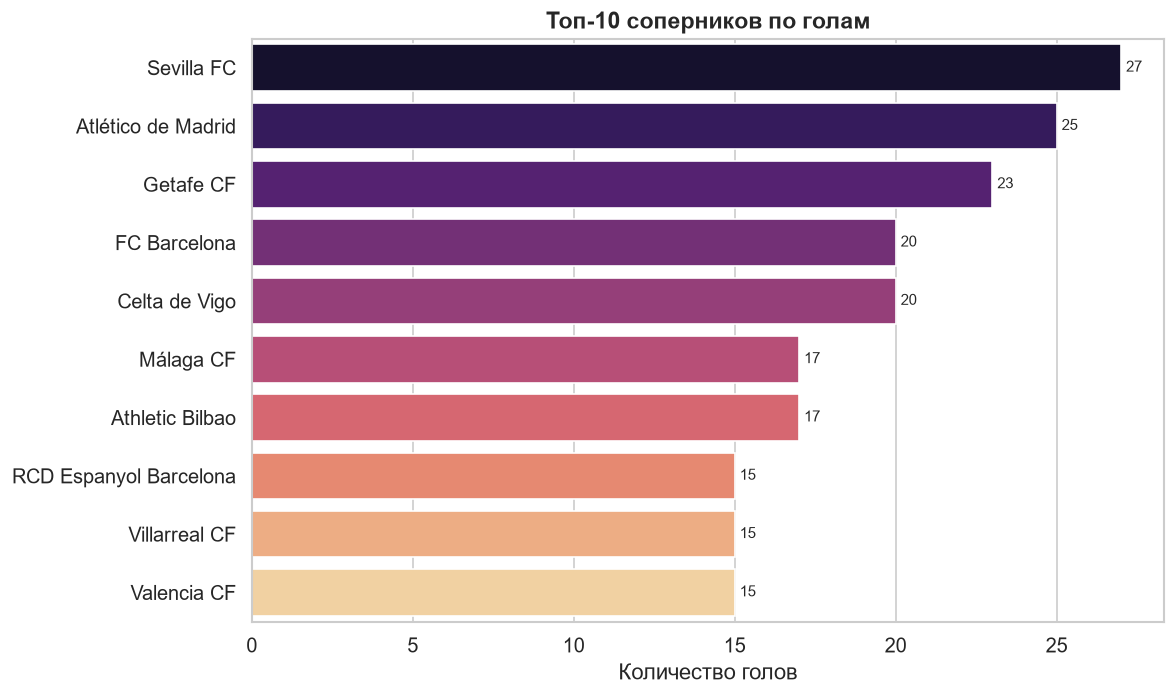

In [23]:
opponent_counts = (
    df["opponent"]
    .value_counts()
    .head(10)
    .reset_index()
)
opponent_counts.columns = ["opponent", "goals"]

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    data=opponent_counts,
    y="opponent",
    x="goals",
    hue="opponent",      
    palette="magma",
    legend=False,
    ax=ax
)
ax.set_title("Топ-10 соперников по голам", fontsize=14, weight="bold")
ax.set_xlabel("Количество голов")
ax.set_ylabel("")

for container in ax.containers:
    ax.bar_label(container, fontsize=9, padding=3)

plt.tight_layout()
plt.savefig(PLOTS_DIR / "top_opponents.png")
plt.show()

## 8. Связи между числовыми признаками

Проверим линейные зависимости между числовыми колонками.

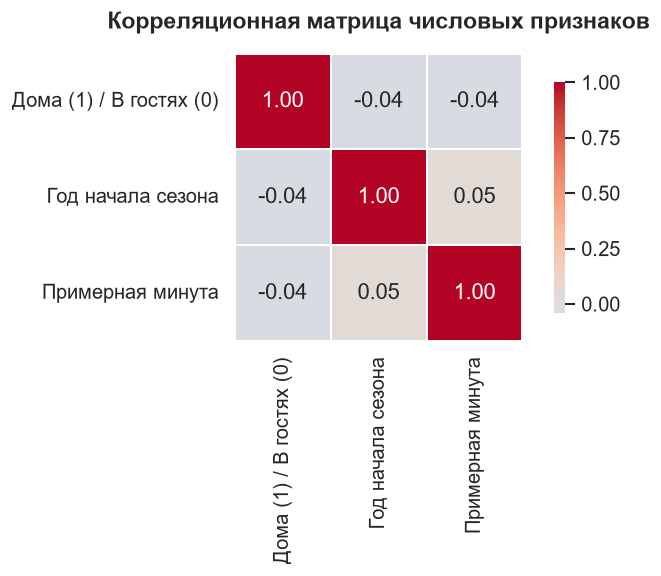

In [ ]:

numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
numeric_cols = [col for col in numeric_cols if df[col].notna().sum() > 0 and col != "goal_minute"]


corr = df[numeric_cols].corr(numeric_only=True)


rename_dict = {
    "is_home_goal": "Дома (1) / В гостях (0)",
    "season_start": "Год начала сезона",
    "minute_approx": "Примерная минута"
}
corr = corr.rename(index=rename_dict, columns=rename_dict)


fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=1,
    cbar_kws={"shrink": 0.8},
    ax=ax
)
ax.set_title("Корреляционная матрица числовых признаков", fontsize=14, weight="bold", pad=15)

plt.tight_layout()
plt.savefig(PLOTS_DIR / "correlation_matrix.png")
plt.show()

## Ключевые выводы EDA

1. **Пик результативности по сезонам:** 2014/2015
2. **Самый результативный турнир:** Laliga
3. **Любимый интервал минут:** 76-90
4. **Самый «удобный» соперник:** Sevilla

> Все графики сохранены в `assets/plots/`. 